In [ ]:
!pip install imbalanced-learn -q

In [ ]:
import warnings
warnings.filterwarnings('ignore')
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (roc_auc_score, roc_curve, average_precision_score,
                              precision_recall_curve, classification_report,
                              confusion_matrix, ConfusionMatrixDisplay)
from imblearn.over_sampling import SMOTE

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving hospital_readmissions_30k.csv to hospital_readmissions_30k.csv


In [ ]:
df = pd.read_csv(list(uploaded.keys())[0])
df.head()

,patient_id,age,gender,blood_pressure,cholesterol,bmi,diabetes,hypertension,medication_count,length_of_stay,discharge_destination,readmitted_30_days
0,1,74,Other,130/72,240,31.5,Yes,No,5,1,Nursing_Facility,Yes
1,2,46,Female,120/92,292,36.3,No,No,4,3,Nursing_Facility,No
2,3,89,Other,135/78,153,30.3,No,Yes,1,1,Home,No
3,4,84,Female,123/80,153,31.5,No,Yes,3,10,Home,No
4,5,32,Other,135/84,205,18.4,No,Yes,6,4,Nursing_Facility,No


In [ ]:
df.info()
print(df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   patient_id             30000 non-null  int64  
 1   age                    30000 non-null  int64  
 2   gender                 30000 non-null  object 
 3   blood_pressure         30000 non-null  object 
 4   cholesterol            30000 non-null  int64  
 5   bmi                    30000 non-null  float64
 6   diabetes               30000 non-null  object 
 7   hypertension           30000 non-null  object 
 8   medication_count       30000 non-null  int64  
 9   length_of_stay         30000 non-null  int64  
 10  discharge_destination  30000 non-null  object 
 11  readmitted_30_days     30000 non-null  object 
dtypes: float64(1), int64(5), object(6)
memory usage: 2.7+ MB
patient_id               0
age                      0
gender                   0
blood_pressure      

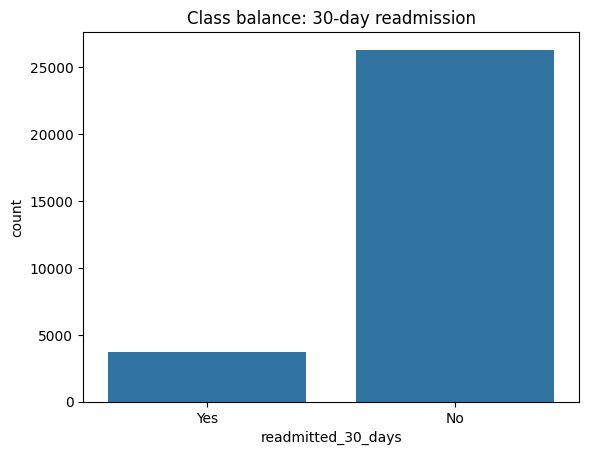

readmitted_30_days
No     0.877533
Yes    0.122467
Name: proportion, dtype: float64


In [ ]:
sns.countplot(x='readmitted_30_days', data=df)
plt.title('Class balance: 30-day readmission')
plt.show()
print(df['readmitted_30_days'].value_counts(normalize=True))

In [ ]:
df = df.drop(columns=['patient_id'])

In [ ]:
bp_split = df['blood_pressure'].str.split('/', expand=True)
df['systolic_bp'] = bp_split[0].astype(int)
df['diastolic_bp'] = bp_split[1].astype(int)
df = df.drop(columns=['blood_pressure'])

In [ ]:
df['readmitted_30_days'] = df['readmitted_30_days'].map({'Yes': 1, 'No': 0})
df['diabetes'] = df['diabetes'].map({'Yes': 1, 'No': 0})
df['hypertension'] = df['hypertension'].map({'Yes': 1, 'No': 0})

In [ ]:
df['age_group'] = pd.cut(df['age'], bins=[0, 40, 60, 75, 100],
                          labels=['<40', '40-60', '60-75', '75+'])

In [ ]:
df = pd.get_dummies(df, columns=['gender', 'discharge_destination', 'age_group'],
                    drop_first=True)

In [ ]:
X = df.drop(columns=['readmitted_30_days'])
y = df['readmitted_30_days']
X = X.astype(float)

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

In [ ]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
param_grid = {'C': [0.001, 0.01, 0.1, 1, 10, 100]}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
base_model = LogisticRegression(penalty='l2', solver='liblinear',
                                 class_weight='balanced', max_iter=1000, random_state=42)
grid = GridSearchCV(base_model, param_grid, scoring='roc_auc', cv=cv, n_jobs=-1)
grid.fit(X_train_scaled, y_train)
print('Best C:', grid.best_params_, 'CV ROC-AUC:', grid.best_score_)

Best C: {'C': 0.001} CV ROC-AUC: 0.5822906567869122


In [ ]:
model = grid.best_estimator_
y_prob = model.predict_proba(X_test_scaled)[:, 1]
y_pred = model.predict(X_test_scaled)

In [ ]:
roc_auc = roc_auc_score(y_test, y_prob)
pr_auc = average_precision_score(y_test, y_prob)
print('ROC-AUC:', round(roc_auc, 4))
print('PR-AUC :', round(pr_auc, 4))
print(classification_report(y_test, y_pred, target_names=['No readmit', 'Readmit']))

ROC-AUC: 0.5623
PR-AUC : 0.1523
              precision    recall  f1-score   support

  No readmit       0.89      0.70      0.78      5265
     Readmit       0.16      0.40      0.23       735

    accuracy                           0.66      6000
   macro avg       0.53      0.55      0.51      6000
weighted avg       0.80      0.66      0.72      6000



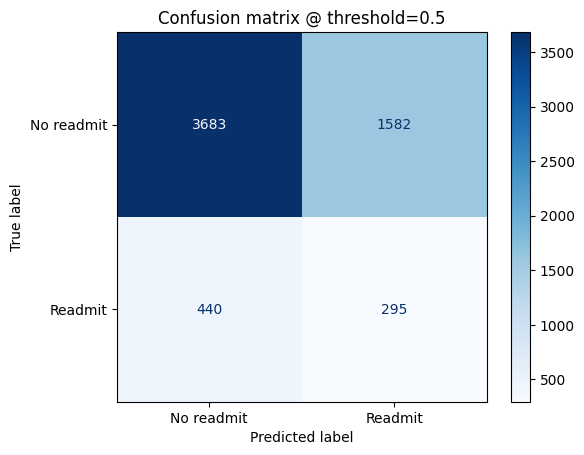

In [ ]:
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=['No readmit', 'Readmit']).plot(cmap='Blues')
plt.title('Confusion matrix @ threshold=0.5')
plt.show()

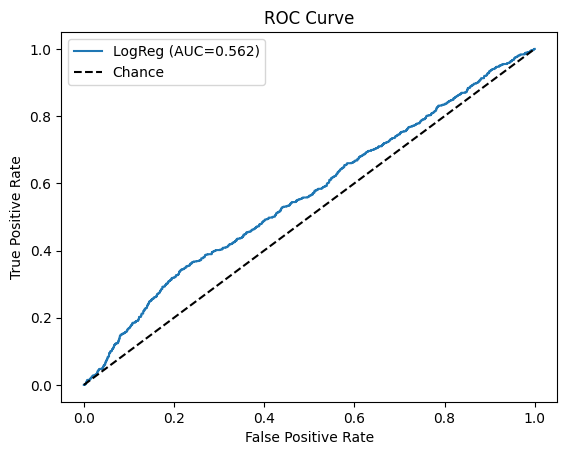

In [ ]:
fpr, tpr, _ = roc_curve(y_test, y_prob)
plt.plot(fpr, tpr, label=f'LogReg (AUC={roc_auc:.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Chance')
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.title('ROC Curve'); plt.legend(); plt.show()

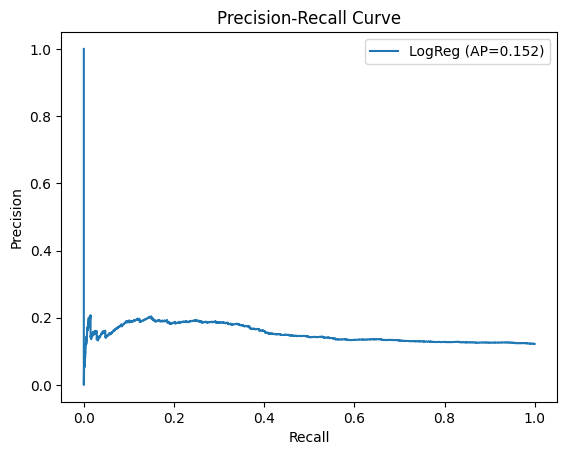

In [ ]:
prec, rec, pr_thresholds = precision_recall_curve(y_test, y_prob)
plt.plot(rec, prec, label=f'LogReg (AP={pr_auc:.3f})')
plt.xlabel('Recall'); plt.ylabel('Precision')
plt.title('Precision-Recall Curve'); plt.legend(); plt.show()

In [ ]:
FN_COST = 5
FP_COST = 1

thresholds = np.linspace(0.01, 0.99, 99)
costs = []
for t in thresholds:
    preds_t = (y_prob >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, preds_t).ravel()
    costs.append(fn * FN_COST + fp * FP_COST)

best_t = thresholds[np.argmin(costs)]
print('Cost-optimal threshold:', round(best_t, 3), 'min cost:', min(costs))

Cost-optimal threshold: 0.58 min cost: 3538


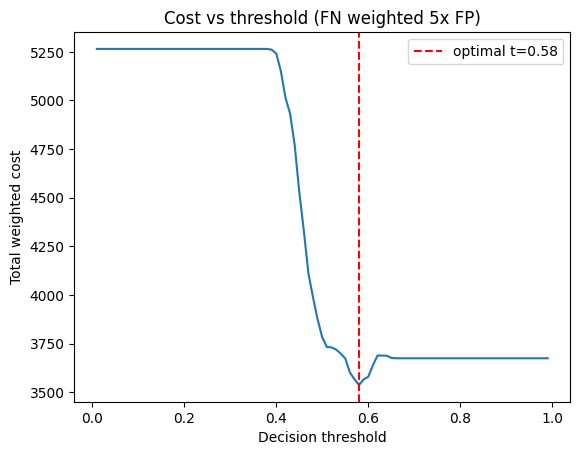

In [ ]:
plt.plot(thresholds, costs)
plt.axvline(best_t, color='red', linestyle='--', label=f'optimal t={best_t:.2f}')
plt.xlabel('Decision threshold'); plt.ylabel('Total weighted cost')
plt.title('Cost vs threshold (FN weighted 5x FP)')
plt.legend(); plt.show()

              precision    recall  f1-score   support

  No readmit       0.89      0.83      0.86      5265
     Readmit       0.19      0.28      0.22       735

    accuracy                           0.76      6000
   macro avg       0.54      0.56      0.54      6000
weighted avg       0.81      0.76      0.78      6000



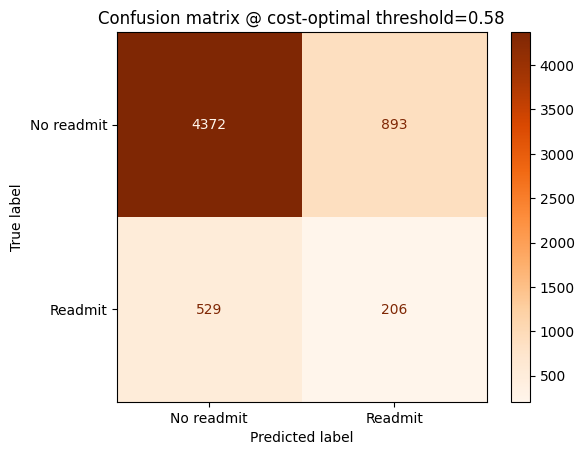

In [ ]:
y_pred_costopt = (y_prob >= best_t).astype(int)
print(classification_report(y_test, y_pred_costopt, target_names=['No readmit', 'Readmit']))
cm2 = confusion_matrix(y_test, y_pred_costopt)
ConfusionMatrixDisplay(cm2, display_labels=['No readmit', 'Readmit']).plot(cmap='Oranges')
plt.title(f'Confusion matrix @ cost-optimal threshold={best_t:.2f}')
plt.show()

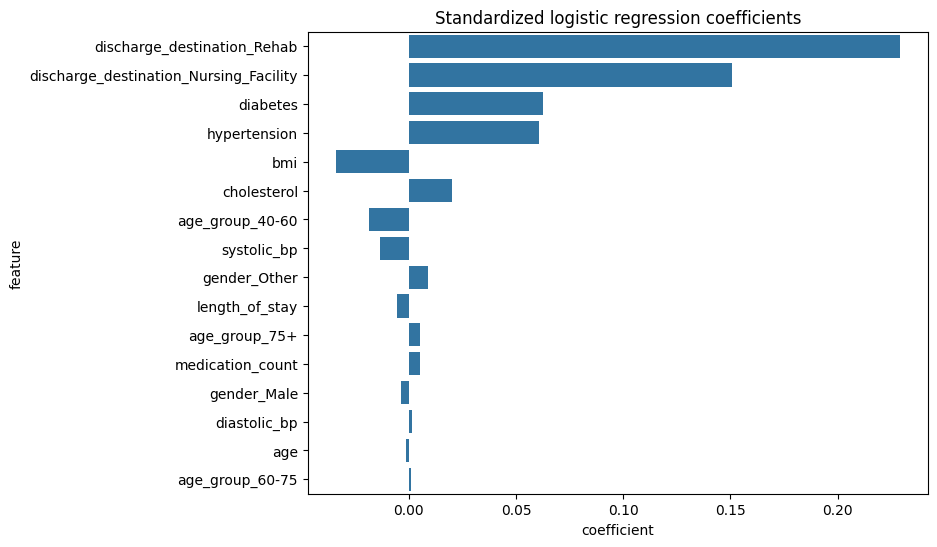

In [ ]:
coef_df = pd.DataFrame({'feature': X.columns, 'coefficient': model.coef_[0]})
coef_df = coef_df.reindex(coef_df.coefficient.abs().sort_values(ascending=False).index)
plt.figure(figsize=(8, 6))
sns.barplot(data=coef_df, x='coefficient', y='feature')
plt.title('Standardized logistic regression coefficients')
plt.show()

In [ ]:
sm = SMOTE(random_state=42)
X_train_sm, y_train_sm = sm.fit_resample(X_train_scaled, y_train)
model_sm = LogisticRegression(penalty='l2', C=grid.best_params_['C'],
                               solver='liblinear', max_iter=1000, random_state=42)
model_sm.fit(X_train_sm, y_train_sm)
y_prob_sm = model_sm.predict_proba(X_test_scaled)[:, 1]
print('SMOTE ROC-AUC:', round(roc_auc_score(y_test, y_prob_sm), 4))
print('SMOTE PR-AUC :', round(average_precision_score(y_test, y_prob_sm), 4))

SMOTE ROC-AUC: 0.5597
SMOTE PR-AUC : 0.1512
